In [2]:

from google.colab import drive
from pathlib import Path
import pandas as pd

# Mount Google Drive at the working location
drive.mount("/content/gdrive")

# Define the path to our synthetic dataset
PROJECT_DIR = Path("/content/gdrive/MyDrive/ChampionsAthleticMap")
CSV_PATH = PROJECT_DIR /"data"/"synthetic"/"synthetic_athlete_profiles.csv"

# Load the dataset into a Pandas DataFrame
df = pd.read_csv(CSV_PATH)

# Display the first five athlete profiles
df.head(5)


Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


,athlete_id,age,sport,position,experience_level,primary_goal,available_days_per_week,equipment,injury_status,scenario_type,scenario_note,is_synthetic,athlete_request
0,SYN001,16,Basketball,Power Forward,Beginner,Improve focus under fatigue,4,Basketball; Hoop; Gym Access,reported_knee_pain,injury_concern,Reports knee pain; requires appropriate cautio...,True,NaN
1,SYN002,16,Basketball,Shooting Guard,Intermediate,Build mental resilience,5,Basketball; Hoop; Cones,reported_ankle_pain,injury_concern,Reports ankle pain; avoid assuming clearance f...,True,NaN
2,SYN003,17,Basketball,Point Guard,Advanced,Improve passing,5,Basketball,unknown,unknown_injury_status,Injury status not supplied; do not interpret a...,True,NaN
3,SYN004,14,Basketball,Center,Beginner,Improve dribbling,3,Basketball,none_reported,limited_equipment,No hoop or gym access reported,True,NaN
4,SYN005,14,Basketball,Power Forward,Intermediate,Build mental resilience,2,Basketball; Hoop; Resistance Bands,none_reported,limited_schedule,Only two training days available,True,NaN


In [3]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Examine column names, data types, and non-null counts
print("\nDataset information:")
df.info()

# Count missing values in each column
print("\nMissing values per column:")
print(df.isna().sum())


Dataset shape: (60, 13)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   athlete_id               60 non-null     object
 1   age                      60 non-null     int64 
 2   sport                    60 non-null     object
 3   position                 60 non-null     object
 4   experience_level         60 non-null     object
 5   primary_goal             60 non-null     object
 6   available_days_per_week  60 non-null     int64 
 7   equipment                60 non-null     object
 8   injury_status            60 non-null     object
 9   scenario_type            60 non-null     object
 10  scenario_note            8 non-null      object
 11  is_synthetic             60 non-null     bool  
 12  athlete_request          2 non-null      object
dtypes: bool(1), int64(2), object(10)
memory usage: 5.8+

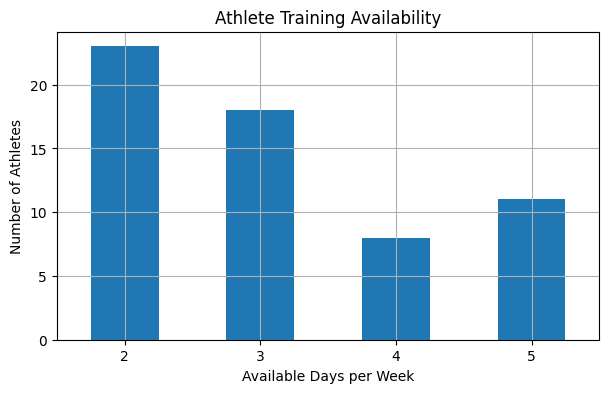

In [5]:
import matplotlib.pyplot as plt

df["available_days_per_week"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Athlete Training Availability")
plt.xlabel("Available Days per Week")
plt.ylabel("Number of Athletes")
plt.xticks(rotation=0)
plt.grid(True)
plt.show()


If an athlete can train only two days per week, generating a four-day training plan violates that constraint.
In our capstone, we call this constraint adherence.We can eventually evaluate it using a simple rule:plan_training_days <= athlete_available_days

primary_goal
Build mental resilience           10
Improve passing                    7
Improve shooting                   6
Improve decision-making            6
Improve court awareness            5
Improve dribbling                  5
Improve focus under fatigue        4
Improve shot selection             4
Improve defense                    4
Improve on-court communication     4
Improve agility                    3
Improve conditioning               2
Name: count, dtype: int64


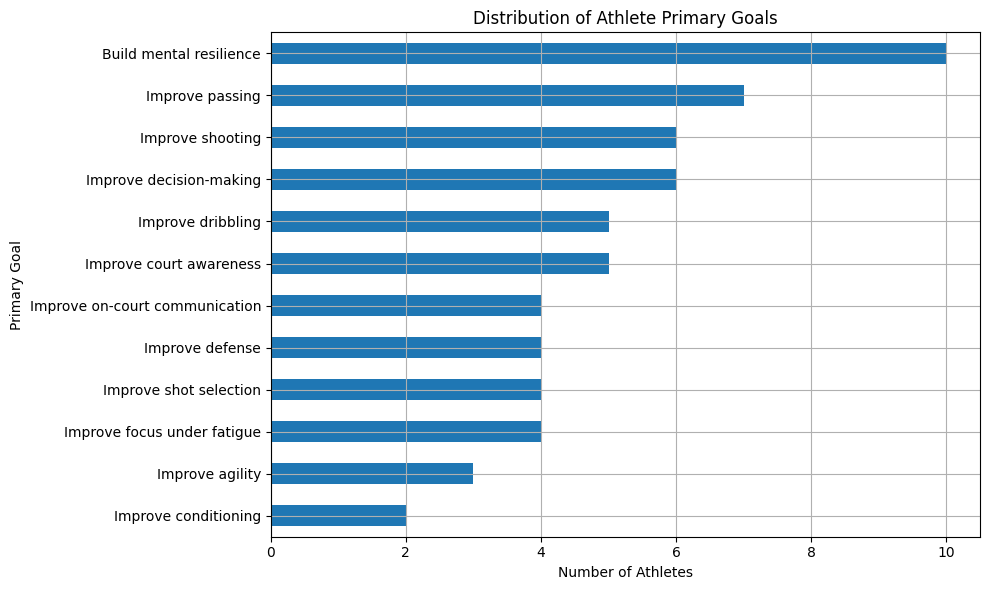

In [7]:

# Count athletes for each primary goal
goal_counts = df["primary_goal"].value_counts()

# Display the counts
print(goal_counts)

# Visualize the distribution
goal_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Distribution of Athlete Primary Goals")
plt.xlabel("Number of Athletes")
plt.ylabel("Primary Goal")
plt.tight_layout()
plt.grid(True)
plt.show()


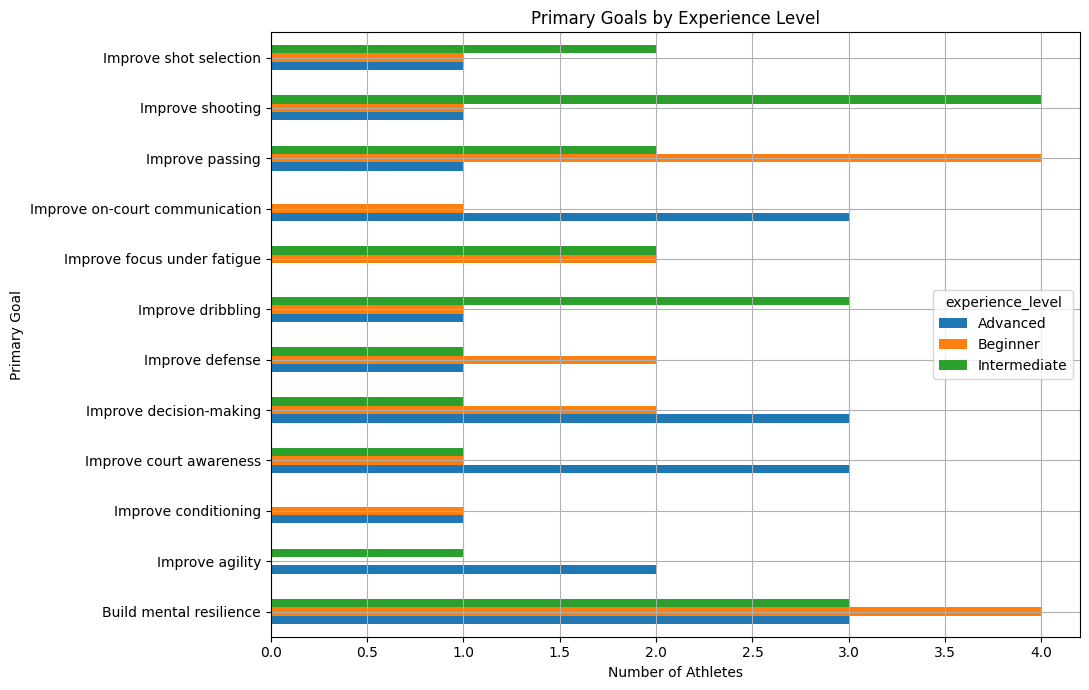

In [8]:

import pandas as pd
import matplotlib.pyplot as plt

# Count goals within each experience level
goal_experience = pd.crosstab(
    df["primary_goal"],
    df["experience_level"]
)

# Visualize the relationship
goal_experience.plot(
    kind="barh",
    figsize=(11, 7)
)

plt.title("Primary Goals by Experience Level")
plt.xlabel("Number of Athletes")
plt.ylabel("Primary Goal")
plt.tight_layout()
plt.grid(True)
plt.show()


scenario_type
standard                      52
injury_concern                 2
limited_equipment              1
unknown_injury_status          1
limited_schedule               1
excessive_training_request     1
advanced_drill_request         1
conflicting_constraints        1
Name: count, dtype: int64


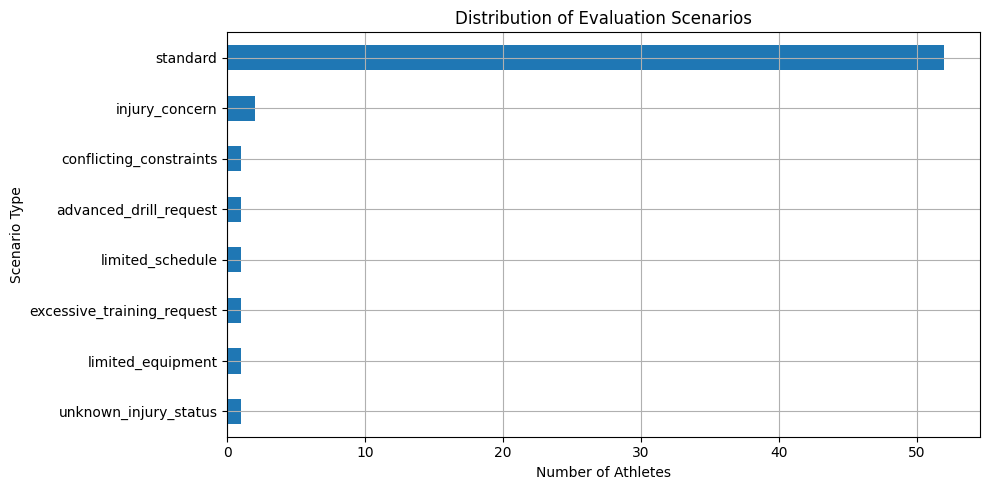

In [10]:

# Count each type of evaluation scenario
scenario_counts = df["scenario_type"].value_counts()

print(scenario_counts)

# Visualize scenario distribution
scenario_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Distribution of Evaluation Scenarios")
plt.xlabel("Number of Athletes")
plt.ylabel("Scenario Type")
plt.tight_layout()
plt.grid(True)
plt.show()


### EDA Summary — Synthetic Athlete Profiles

The synthetic dataset contains 60 fictional youth basketball athlete profiles with 13 attributes. The profiles cover ages 13–17, five basketball positions, and three experience levels.

**Key Findings**

- Age and experience-level distributions are balanced, with 12 athletes per age and 20 per experience level.
- Training availability varies from 2 to 5 days per week. Most athletes (68.3%) are available for only 2–3 days.
- The dataset includes 12 primary development goals, with mental resilience being the most frequent.
- There are 52 standard profiles and 8 special-case profiles designed to test safety and constraint handling.
- Required athlete attributes are complete. Missing values in `scenario_note` and `athlete_request` represent optional information.

**Evaluation Implications**

The dataset provides consistent inputs for comparing four AI configurations. Evaluation should measure personalization, goal alignment, schedule and equipment adherence, evidence grounding, and safety.

**Limitations**

The dataset is synthetic and does not represent the real-world distribution of youth basketball athletes. Some goals and special scenarios have very few examples, limiting the strength of conclusions for individual categories.